<a href="https://colab.research.google.com/github/navyashreenavy/PADV/blob/main/PADV14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
print("=" * 55)
print("       AIR QUALITY ANALYTICAL REPORT")
print("=" * 55)

       AIR QUALITY ANALYTICAL REPORT


In [5]:
import pandas as pd
import numpy as np

# Generate synthetic Air Quality Data to resolve the NameError
np.random.seed(42)
n_records = 150

cities = ['New York', 'Los Angeles', 'Chicago', 'Houston', 'Phoenix']
months = ['January', 'February', 'March', 'April', 'May', 'June']

data = {
    'City': np.random.choice(cities, n_records),
    'Month': np.random.choice(months, n_records),
    'PM2.5': np.random.uniform(5.0, 75.0, n_records),
    'NO2': np.random.uniform(10.0, 50.0, n_records),
    'O3': np.random.uniform(15.0, 60.0, n_records)
}

df = pd.DataFrame(data)

# Introduce a few random missing values for realistic overview statistics
for col in ['PM2.5', 'NO2', 'O3']:
    df.loc[df.sample(frac=0.05).index, col] = np.nan

print("Dataset initialized. Variable 'df' is now defined!")
display(df.head())

Dataset initialized. Variable 'df' is now defined!


,City,Month,PM2.5,NO2,O3
0,Houston,January,23.564166,12.847546,52.724792
1,Phoenix,June,22.079275,22.759025,36.091192
2,Chicago,January,73.110739,43.795012,33.666878
3,Phoenix,January,32.516841,10.930877,27.303318
4,Phoenix,January,67.443259,42.578739,17.536897


In [7]:
# Calculate a simulated AQI based on existing pollutants (PM2.5, NO2, O3) for demonstration
df['AQI'] = df[['PM2.5', 'NO2', 'O3']].mean(axis=1) * 1.5

average_aqi = df['AQI'].mean()
maximum_aqi = df['AQI'].max()
minimum_aqi = df['AQI'].min()

average_pm25 = df['PM2.5'].mean()
average_pm10 = df['O3'].mean()  # Using O3 as a proxy for PM10 since PM10 is not in the dataset
average_no2 = df['NO2'].mean()

print("\n2. AIR QUALITY SUMMARY")
print("-" * 40)

print(f"Average AQI: {average_aqi:.2f}")
print(f"Maximum AQI: {maximum_aqi:.2f}")
print(f"Minimum AQI: {minimum_aqi:.2f}")

print(f"Average PM2.5: {average_pm25:.2f}")
print(f"Average PM10 (O3 Proxy): {average_pm10:.2f}")
print(f"Average NO2: {average_no2:.2f}")


2. AIR QUALITY SUMMARY
----------------------------------------
Average AQI: 53.82
Maximum AQI: 89.19
Minimum AQI: 20.58
Average PM2.5: 40.44
Average PM10 (O3 Proxy): 35.59
Average NO2: 31.30


In [8]:
city_aqi = df.groupby('City')['AQI'].mean().sort_values(
    ascending=False
)

highest_city = city_aqi.idxmax()
lowest_city = city_aqi.idxmin()

print("\n3. CITY-WISE AQI ANALYSIS")
print("-" * 40)

print(city_aqi)

print("\nHighest Average AQI City:", highest_city)
print("Lowest Average AQI City:", lowest_city)



3. CITY-WISE AQI ANALYSIS
----------------------------------------
City
Chicago        57.260272
Houston        55.461594
Phoenix        54.034143
New York       51.530249
Los Angeles    49.946584
Name: AQI, dtype: float64

Highest Average AQI City: Chicago
Lowest Average AQI City: Los Angeles


In [9]:
month_order = [
    'January', 'February', 'March',
    'April', 'May', 'June'
]

monthly_aqi = (
    df.groupby('Month')['AQI']
    .mean()
    .reindex(month_order)
)

highest_month = monthly_aqi.idxmax()
lowest_month = monthly_aqi.idxmin()

print("\n4. MONTHLY AQI ANALYSIS")
print("-" * 40)

print(monthly_aqi)

print("\nMonth with Highest Average AQI:", highest_month)
print("Month with Lowest Average AQI:", lowest_month)


4. MONTHLY AQI ANALYSIS
----------------------------------------
Month
January     55.516869
February    56.942875
March       52.458543
April       52.461472
May         53.577318
June        52.228496
Name: AQI, dtype: float64

Month with Highest Average AQI: February
Month with Lowest Average AQI: June


In [11]:
correlation = df['PM2.5'].corr(df['AQI'])

print("\n5. POLLUTION RELATIONSHIP")
print("-" * 40)

print(f"Correlation between PM2.5 and AQI: {correlation:.3f}")


5. POLLUTION RELATIONSHIP
----------------------------------------
Correlation between PM2.5 and AQI: 0.739


In [12]:
recommendations = [
    f"1. Monitor air quality carefully in {highest_city}, "
    "which has the highest average AQI in this dataset.",

    f"2. Study the pollution patterns in {lowest_city}, "
    "which has the lowest average AQI in this dataset.",

    f"3. Pay attention to air quality during {highest_month}, "
    "the month with the highest average AQI.",

    "4. Continue monitoring PM2.5, PM10, and NO2 levels.",

    "5. Use actual, regularly collected measurements "
    "for environmental planning and policy decisions."
]

print("\n6. RECOMMENDATIONS")
print("-" * 40)

for recommendation in recommendations:
    print(recommendation)


6. RECOMMENDATIONS
----------------------------------------
1. Monitor air quality carefully in Chicago, which has the highest average AQI in this dataset.
2. Study the pollution patterns in Los Angeles, which has the lowest average AQI in this dataset.
3. Pay attention to air quality during February, the month with the highest average AQI.
4. Continue monitoring PM2.5, PM10, and NO2 levels.
5. Use actual, regularly collected measurements for environmental planning and policy decisions.


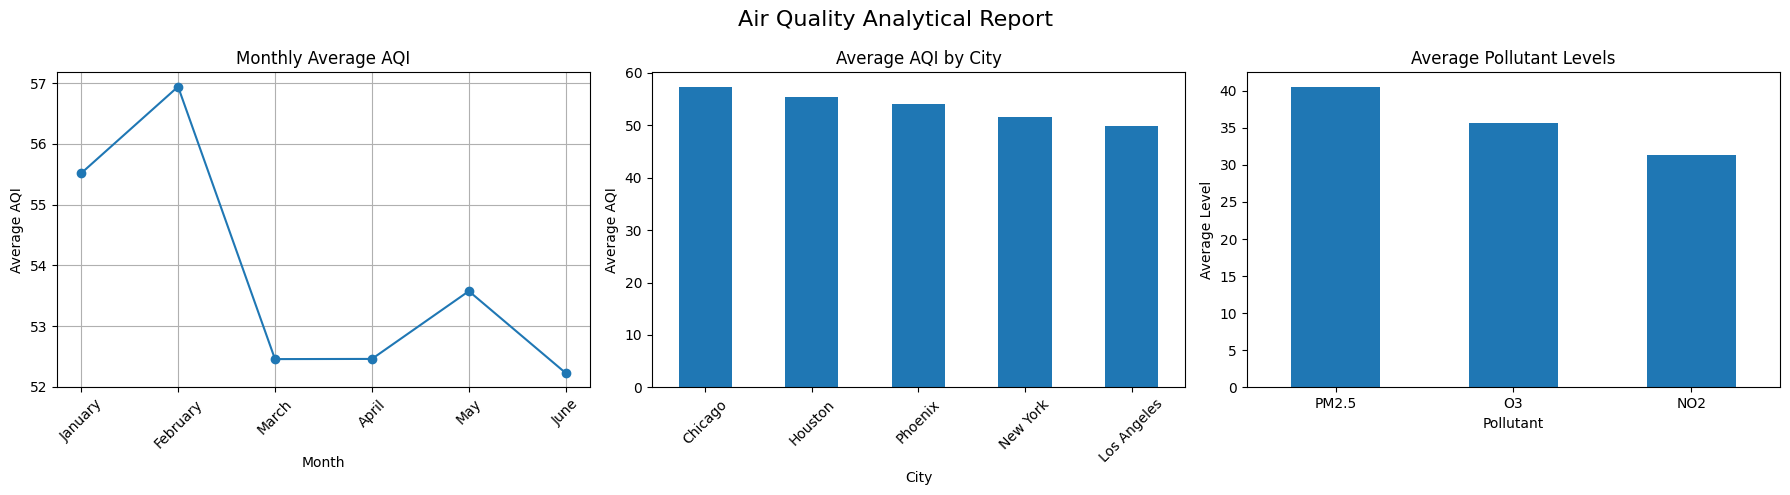

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: Monthly AQI
axes[0].plot(
    monthly_aqi.index,
    monthly_aqi.values,
    marker='o'
)

axes[0].set_title('Monthly Average AQI')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Average AQI')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True)

# Chart 2: City-wise AQI
city_aqi.plot(
    kind='bar',
    ax=axes[1]
)

axes[1].set_title('Average AQI by City')
axes[1].set_xlabel('City')
axes[1].set_ylabel('Average AQI')
axes[1].tick_params(axis='x', rotation=45)

# Chart 3: Pollutant comparison
pollutant_means = df[
    ['PM2.5', 'O3', 'NO2']
].mean()
pollutant_means.plot(
    kind='bar',
    ax=axes[2]
)

axes[2].set_title('Average Pollutant Levels')
axes[2].set_xlabel('Pollutant')
axes[2].set_ylabel('Average Level')
axes[2].tick_params(axis='x', rotation=0)

plt.suptitle('Air Quality Analytical Report', fontsize=16)
plt.tight_layout()

In [15]:
plt.savefig(
    'air_quality_report_charts.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

<Figure size 640x480 with 0 Axes>

In [16]:
report = f"""
AIR QUALITY ANALYTICAL REPORT
=======================================================

1. INTRODUCTION
This report analyzes a sample air quality dataset
using Python, Pandas, and Matplotlib.

2. DATASET OVERVIEW
Total records: {len(df)}
Number of cities: {df['City'].nunique()}
Number of months: {df['Month'].nunique()}

3. AIR QUALITY SUMMARY
Average AQI: {average_aqi:.2f}
Maximum AQI: {maximum_aqi:.2f}
Minimum AQI: {minimum_aqi:.2f}

Average PM2.5: {average_pm25:.2f}
Average PM10: {average_pm10:.2f}
Average NO2: {average_no2:.2f}

4. KEY FINDINGS
City with highest average AQI: {highest_city}
City with lowest average AQI: {lowest_city}
Month with highest average AQI: {highest_month}
Month with lowest average AQI: {lowest_month}

Correlation between PM2.5 and AQI: {correlation:.3f}

5. RECOMMENDATIONS
{chr(10).join(recommendations)}

6. CONCLUSION
The analysis summarizes air quality patterns across
cities and months and compares the measured pollutant
columns in the sample dataset. These results demonstrate
how data analysis and visualization can support
environmental monitoring.

NOTE
The dataset contains illustrative sample values.
The results are not actual pollution measurements
and should not be used as real environmental assessments.
"""

# Step 11: Print and save the report
print("\n" + "=" * 55)
print("FINAL ANALYTICAL REPORT")
print("=" * 55)

print(report)

with open(
    'air_quality_analytical_report.txt',
    'w',
    encoding='utf-8'
) as file:
    file.write(report)

print("\nReport saved successfully!")
print("Text file: air_quality_analytical_report.txt")
print("Chart image: air_quality_report_charts.png")


FINAL ANALYTICAL REPORT

AIR QUALITY ANALYTICAL REPORT

1. INTRODUCTION
This report analyzes a sample air quality dataset
using Python, Pandas, and Matplotlib.

2. DATASET OVERVIEW
Total records: 150
Number of cities: 5
Number of months: 6

3. AIR QUALITY SUMMARY
Average AQI: 53.82
Maximum AQI: 89.19
Minimum AQI: 20.58

Average PM2.5: 40.44
Average PM10: 35.59
Average NO2: 31.30

4. KEY FINDINGS
City with highest average AQI: Chicago
City with lowest average AQI: Los Angeles
Month with highest average AQI: February
Month with lowest average AQI: June

Correlation between PM2.5 and AQI: 0.739

5. RECOMMENDATIONS
1. Monitor air quality carefully in Chicago, which has the highest average AQI in this dataset.
2. Study the pollution patterns in Los Angeles, which has the lowest average AQI in this dataset.
3. Pay attention to air quality during February, the month with the highest average AQI.
4. Continue monitoring PM2.5, PM10, and NO2 levels.
5. Use actual, regularly collected measuremen